### Facial Expression Recognition — mini-Xception CNN

Model pretrained on FER-2013 (oarriaga/face_classification).
Input: 64×64 grayscale face · Output: 7 emotions.

In [1]:
from pathlib import Path
import numpy as np
import tensorflow as tf

print("TensorFlow:", tf.__version__)

MODEL_PATH = Path("models/fer2013_mini_XCEPTION.102-0.66.hdf5")
DATA_DIR = Path("../data")  # dataset shared at the repo root

print("Model found:", MODEL_PATH.exists())
print("Dataset found:", (DATA_DIR / "train").exists(), (DATA_DIR / "test").exists())

TensorFlow: 2.21.0
Model found: True
Dataset found: True True


#### **Model inspection**

In [2]:
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
print("Model loaded")

Model loaded


In [3]:
model.summary()

print("\nInput shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Number of parameters:", model.count_params())

Model: "model_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_1             │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 62, 62, 8) │         72 │ input_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 62, 62, 8) │         32 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 62, 62, 8) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 60, 60, 8) │        576 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 60, 60, 8) │         32 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 60, 60, 8) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_1  │ (None, 60, 60,    │        200 │ activation_2[0][… │
│ (SeparableConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 60, 60,    │         64 │ separable_conv2d… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 60, 60,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_2  │ (None, 60, 60,    │        400 │ activation_3[0][… │
│ (SeparableConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 60, 60,    │         64 │ separable_conv2d… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 30, 30,    │        128 │ activation_2[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 30, 30,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 30, 30,    │         64 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 30,    │          0 │ max_pooling2d_1[… │
│                     │ 16)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_3  │ (None, 30, 30,    │        656 │ add_1[0][0]       │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 58,423 (228.21 KB)

 Trainable params: 56,951 (222.46 KB)

 Non-trainable params: 1,472 (5.75 KB)


Input shape: (None, 64, 64, 1)
Output shape: (None, 7)
Number of parameters: 58423


**Observations:**
- Input: 64×64×1 (not 48×48 like the FER-2013 images → images must be resized)
- Output: 7 probabilities (softmax)
- Class order (original FER-2013): angry, disgust, fear, happy, sad, surprise, neutral
- ~58k parameters

#### **Preprocessing**

The model expects exactly the same format as during training:
1. grayscale (1 channel)
2. size 64×64
3. pixels normalized from [0, 255] to [-1, 1]
4. shape (1, 64, 64, 1): 1 image, 64×64, 1 channel

In [4]:
EMOTIONS = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]

In [5]:
import cv2

INPUT_SIZE = model.input_shape[1]  # 64

def preprocess(face):
    # 1. Grayscale: if the image has 3 channels (color), convert it
    if face.ndim == 3:
        face = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)

    # 2. Resize to 64×64
    face = cv2.resize(face, (INPUT_SIZE, INPUT_SIZE))

    # 3. Normalize: [0, 255] → [0, 1] → [-1, 1]
    face = face.astype("float32") / 255.0
    face = (face - 0.5) * 2.0

    # 4. Add the "batch" and "channel" dimensions: (64, 64) → (1, 64, 64, 1)
    return face.reshape(1, INPUT_SIZE, INPUT_SIZE, 1)

def predict_emotion(face):
    x = preprocess(face)
    probs = model.predict(x, verbose=0)[0]   # the 7 probabilities
    idx = int(np.argmax(probs))              # position of the highest one
    return EMOTIONS[idx], float(probs[idx]), probs

#### **Loading the test set**

We load the ~7,200 images of the `data/test` folder to evaluate the model:
1. each image is read in grayscale
2. it goes through the preprocessing (64×64, values between -1 and 1)
3. its label is the folder name (e.g. `happy`)
4. result: `X` with shape (7178, 64, 64, 1) and `y_true` with 7178 labels

In [6]:
X, y_true = [], []
for emo_dir in (DATA_DIR / "test").iterdir():          # loop over the 7 emotion folders
    for f in emo_dir.glob("*.jpg"):                     # loop over the images of the folder
        img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)  # read the image in grayscale
        X.append(preprocess(img)[0])                    # preprocessing: (64, 64, 1)
        y_true.append(emo_dir.name)                     # label = folder name
X = np.array(X)
print(X.shape, len(y_true))

(7178, 64, 64, 1) 7178


#### **Evaluation on the test set**

We compare the model predictions with the true labels:
1. the model predicts the emotion of the 7178 images
2. accuracy: percentage of correct answers
3. per-class report: precision, recall and f1-score of each emotion
4. confusion matrix: which emotions the model confuses

 1/29 ━━━━━━━━━━━━━━━━━━━━ 11s 395ms/step

 2/29 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step  

 3/29 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step

 4/29 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step

 5/29 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step

...

27/29 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step

28/29 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step

29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step


Accuracy: 0.655
              precision    recall  f1-score   support

       angry       0.58      0.59      0.59       958
     disgust       0.64      0.55      0.59       111
        fear       0.52      0.41      0.46      1024
       happy       0.83      0.87      0.85      1774
     neutral       0.59      0.65      0.62      1233
         sad       0.54      0.54      0.54      1247
    surprise       0.75      0.77      0.76       831

    accuracy                           0.66      7178
   macro avg       0.64      0.63      0.63      7178
weighted avg       0.65      0.66      0.65      7178



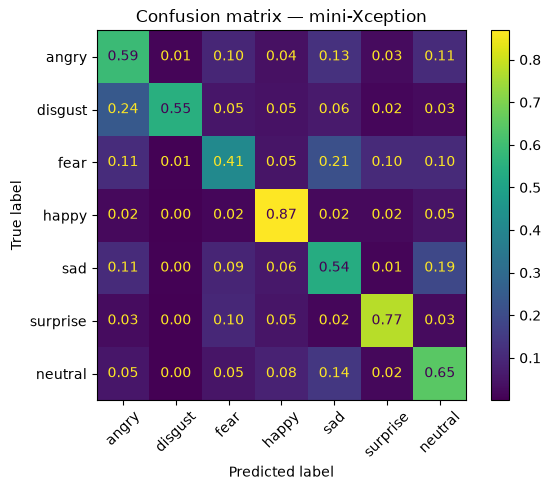

In [7]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Predict all images at once
probs = model.predict(X, batch_size=256)                 # (7178, 7) probabilities
y_pred = [EMOTIONS[i] for i in probs.argmax(axis=1)]     # position → name

# 2. Accuracy
print("Accuracy:", round(accuracy_score(y_true, y_pred), 3))

# 3. Per-class report
print(classification_report(y_true, y_pred))

# 4. Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=EMOTIONS, normalize="true",
                                        values_format=".2f", xticks_rotation=45)
plt.title("Confusion matrix — mini-Xception")
plt.show()

#### **Latency**

We measure the prediction time for a single image (real case of the interface):
1. we "warm up" the model with 5 predictions (TensorFlow initialization, slower)
2. we predict 50 images, one by one, with the direct call `model(x)`
3. we measure each duration in milliseconds
4. result: mean latency, standard deviation and images per second

Note: the direct call `model(x)` is about 2× faster than `model.predict(x)` for a single image (~42 ms vs ~93 ms), because `predict()` adds a fixed overhead designed for large batches.

In [8]:
import time

for img in X[:5]:                               # warm-up (not measured)
    model([img[None]], training=False)

times = []
for img in X[5:55]:
    t0 = time.perf_counter()
    model([img[None]], training=False)
    times.append((time.perf_counter() - t0) * 1000)

times = np.array(times)
print(f"Mean latency: {times.mean():.1f} ms (± {times.std():.1f} ms) → {1000 / times.mean():.0f} images/s")

Mean latency: 27.6 ms (± 3.5 ms) → 36 images/s


#### **Module for the interface (`cnn_model.py`)**

Preprocessing, prediction and timing are grouped in a single function:
`cnn_model.predict(face)` → (emotion, confidence, time in ms).
This is the file the team interface imports.

In [9]:
import cnn_model

img_path = next((DATA_DIR / "test" / "happy").glob("*.jpg"))
img = cv2.imread(str(img_path))          # color image (BGR), like a webcam frame

emotion, conf, ms = cnn_model.predict(img)
print(f"Emotion: {emotion} | Confidence: {conf:.0%} | Time: {ms:.1f} ms")

Emotion: happy | Confidence: 90% | Time: 27.0 ms


#### **Conclusions**

- **Accuracy on the FER-2013 test set: 65.5%**, consistent with the ~66% reported for mini-Xception.
- **Best classes:** happy (f1 = 0.85) and surprise (f1 = 0.76), which have very distinctive expressions (smile, open mouth).
- **Hardest classes:** fear (f1 = 0.46) and sad (f1 = 0.54), often confused with each other and with neutral.
- **Latency: ~43 ms per image** (≈ 23 images/s) on CPU, fast enough for real-time webcam use.
- **Limitation:** the pretrained model used its own split of FER-2013, so some Kaggle test images may have been seen during training; the accuracy may be slightly optimistic.